In [73]:
import os
import re
import numpy as np
from pathlib import Path
import skrf as rf

# Asegurar que el CWD es la carpeta del notebook
_notebook_dir = Path(__file__).parent if "__file__" in dir() else Path().resolve()
os.chdir(_notebook_dir)


def load_s11_from_touchstone(filename):
    """
    Lee un .s1p o .s2p y devuelve:
      freqs_hz: vector de frecuencias en Hz
      gamma_m:  vector complejo con S11 (Gamma_m)
    """
    ntw = rf.Network(str(filename))
    freqs_hz = ntw.f  # en Hz
    gamma_m = ntw.s[:, 0, 0]  # S11
    return freqs_hz, gamma_m


def estimate_oneport_error_terms_SOL(
        freqs_hz,
        gamma_m_open,
        gamma_m_short,
        gamma_m_load,
        gamma_open_std=1.0 + 0j,
        gamma_short_std=-1.0 + 0j,
        gamma_load_std=0.0 + 0j):
    """
    Estima e_d(f), e_r(f), e_s(f) para cada frecuencia usando tres mediciones:
    open, short y load, y el modelo:
        Gamma_m = (e_d + e_r * Gamma_std) / (1 - e_s * Gamma_std)

    Se resuelve, para cada frecuencia, el sistema lineal complejo:
        e_d + e_r*Gamma_k + e_s*(Gamma_m_k * Gamma_k) = Gamma_m_k
    con k in {open, short, load}.
    """

    n_freq = len(freqs_hz)
    ed = np.zeros(n_freq, dtype=complex)
    er = np.zeros(n_freq, dtype=complex)
    es = np.zeros(n_freq, dtype=complex)

    Gamma_std = np.array([gamma_open_std, gamma_short_std, gamma_load_std], dtype=complex)

    for i in range(n_freq):
        Gamma_m = np.array([
            gamma_m_open[i],
            gamma_m_short[i],
            gamma_m_load[i]
        ], dtype=complex)

        A = np.zeros((3, 3), dtype=complex)
        b = Gamma_m.copy()

        for k in range(3):
            A[k, 0] = 1.0
            A[k, 1] = Gamma_std[k]
            A[k, 2] = Gamma_m[k] * Gamma_std[k]

        if np.linalg.matrix_rank(A) < 3:
            raise np.linalg.LinAlgError(
                "La matriz de calibracion SOL es singular en una o mas frecuencias. "
                "Verifica que open, short y load sean mediciones distintas y validas."
            )

        x = np.linalg.solve(A, b)

        ed[i] = x[0]
        er[i] = x[1]
        es[i] = x[2]

    return ed, er, es


def _natural_key(path_obj):
    parts = re.split(r"(\d+)", path_obj.stem)
    return [int(p) if p.isdigit() else p.lower() for p in parts]


def collect_standard_measure_files(standard, measures_root="data/calibration"):
    """
    Devuelve todos los archivos de medida para un estandar (open/short/load).
    Si existen .s2p y .s1p del mismo test (mismo stem), prioriza .s2p.
    """
    folder = Path(measures_root) / standard
    if not folder.exists():
        raise FileNotFoundError(f"No existe la carpeta del estandar '{standard}': {folder}")

    s2p_files = sorted(folder.glob("*.s2p"), key=_natural_key)
    s1p_files = sorted(folder.glob("*.s1p"), key=_natural_key)

    by_stem_s2p = {p.stem: p for p in s2p_files}
    by_stem_s1p = {p.stem: p for p in s1p_files}

    selected = []
    all_stems = sorted(set(by_stem_s2p) | set(by_stem_s1p), key=lambda s: _natural_key(Path(s)))
    for stem in all_stems:
        selected.append(by_stem_s2p.get(stem, by_stem_s1p[stem]))

    if not selected:
        raise FileNotFoundError(
            f"No se encontraron medidas .s1p/.s2p para '{standard}' en {folder}"
        )

    return selected


def average_gamma_from_repetitions(file_list, standard_label):
    """
    Carga todas las repeticiones de un estandar y devuelve:
      freqs_hz, gamma_mean, gamma_std
    """
    gammas = []
    freqs_ref = None

    for idx, file_path in enumerate(file_list, start=1):
        freqs_hz, gamma_m = load_s11_from_touchstone(file_path)
        if freqs_ref is None:
            freqs_ref = freqs_hz
        elif not np.allclose(freqs_ref, freqs_hz):
            raise ValueError(
                f"La rejilla de frecuencias no coincide en '{standard_label}'. "
                f"Archivo conflictivo: {file_path}"
            )

        gammas.append(gamma_m)
        print(f"[{standard_label}] rep {idx:02d}: {file_path}")

    gamma_stack = np.vstack(gammas)
    gamma_mean = np.mean(gamma_stack, axis=0)
    gamma_std = np.std(gamma_stack, axis=0)

    print(
        f"[{standard_label}] usadas {len(file_list)} repeticiones. "
        f"Sigma media(|Gamma|)={np.mean(np.abs(gamma_std)):.3e}"
    )

    return freqs_ref, gamma_mean, gamma_std


measures_root = Path("data/calibration")
files_open = collect_standard_measure_files("open", measures_root=measures_root)
files_short = collect_standard_measure_files("short", measures_root=measures_root)
files_load = collect_standard_measure_files("load", measures_root=measures_root)

f_open, gamma_m_open, gamma_std_open = average_gamma_from_repetitions(files_open, "open")
f_short, gamma_m_short, gamma_std_short = average_gamma_from_repetitions(files_short, "short")
f_load, gamma_m_load, gamma_std_load = average_gamma_from_repetitions(files_load, "load")

if not (np.allclose(f_open, f_short) and np.allclose(f_open, f_load)):
    raise ValueError("Las frecuencias de open/short/load no coinciden. Habra que interpolar a una rejilla comun.")

ed, er, es = estimate_oneport_error_terms_SOL(
    f_open,
    gamma_m_open,
    gamma_m_short,
    gamma_m_load,
    gamma_open_std=1.0 + 0j,
    gamma_short_std=-1.0 + 0j,
    gamma_load_std=0.0 + 0j,
)

for i in range(0, len(f_open), max(1, len(f_open) // 10)):
    print(
        f"f = {f_open[i] / 1e6:.3f} MHz : "
        f"e_d = {ed[i]:.4g}, e_r = {er[i]:.4g}, e_s = {es[i]:.4g}"
    )


[open] rep 01: data/calibration/open/test_1.s2p
[open] rep 02: data/calibration/open/test_2.s2p
[open] rep 03: data/calibration/open/test_3.s2p
[open] rep 04: data/calibration/open/test_4.s2p
[open] rep 05: data/calibration/open/test_5.s2p
[open] rep 06: data/calibration/open/test_6.s2p
[open] rep 07: data/calibration/open/test_7.s2p
[open] rep 08: data/calibration/open/test_8.s2p
[open] rep 09: data/calibration/open/test_9.s2p
[open] rep 10: data/calibration/open/test_10.s2p
[open] usadas 10 repeticiones. Sigma media(|Gamma|)=4.843e-03
[short] rep 01: data/calibration/short/test_1.s2p
[short] rep 02: data/calibration/short/test_2.s2p
[short] rep 03: data/calibration/short/test_3.s2p
[short] rep 04: data/calibration/short/test_4.s2p
[short] rep 05: data/calibration/short/test_5.s2p
[short] rep 06: data/calibration/short/test_6.s2p
[short] rep 07: data/calibration/short/test_7.s2p
[short] rep 08: data/calibration/short/test_8.s2p
[short] rep 09: data/calibration/short/test_9.s2p
[short]

In [74]:
np.savez("error_terms_SOL_master.npz",
         freqs_hz=f_open,
         ed=ed,
         er=er,
         es=es)
print("Guardado error_terms_SOL_master.npz")


Guardado error_terms_SOL_master.npz


=== Estadísticas globales de los términos de error ===

e_d:
  |x| mean = 0.002117, std = 0.004193
  angle(x) mean = 54.69 deg, std = 139.52 deg
  Re(x) mean = -0.001542, std = 0.003507
  Im(x) mean = -0.0002733, std = 0.002704

e_r:
  |x| mean = 1.057, std = 0.1751
  angle(x) mean = -4.59 deg, std = 17.78 deg
  Re(x) mean = 0.9916, std = 0.1941
  Im(x) mean = -0.09317, std = 0.3449

e_s:
  |x| mean = 0.01333, std = 0.02436
  angle(x) mean = -12.85 deg, std = 85.17 deg
  Re(x) mean = 0.007924, std = 0.02348
  Im(x) mean = 0.001966, std = 0.01238
Figures saved: *_mag_vs_freq.png, *_phase_vs_freq.png, *_mag_hist.png, *_phase_hist.png


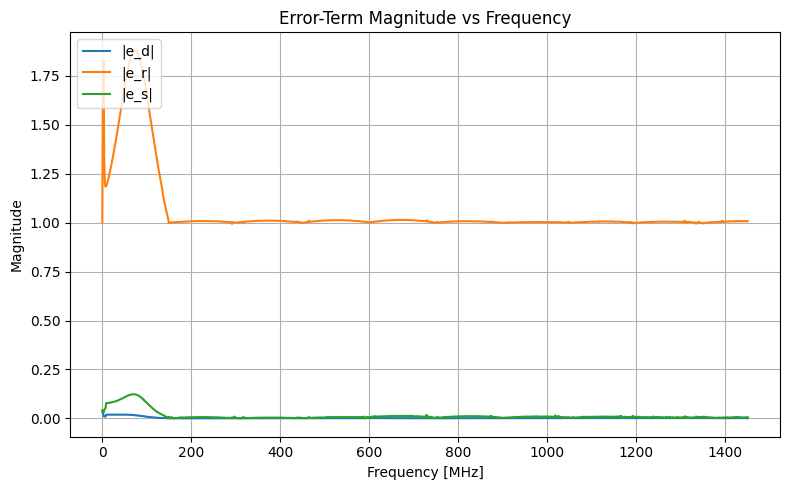

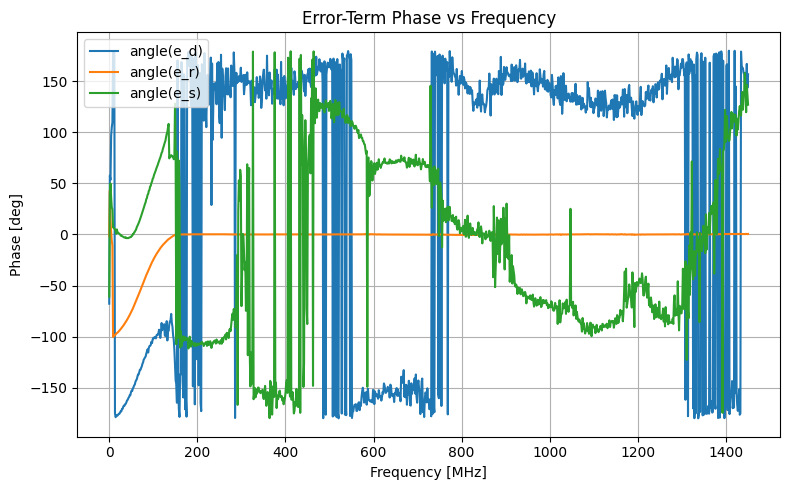

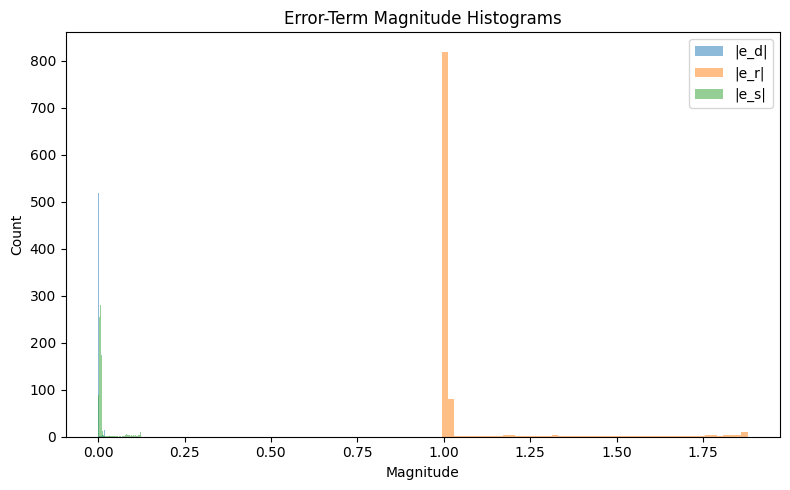

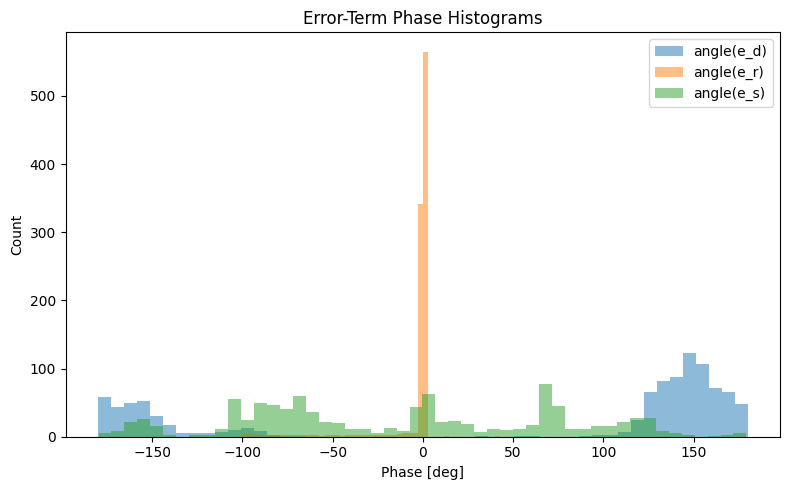

In [117]:
import numpy as np
import matplotlib.pyplot as plt

def load_error_terms(npz_file):
    data = np.load(npz_file)
    freqs_hz = data["freqs_hz"]
    ed = data["ed"]
    er = data["er"]
    es = data["es"]
    return freqs_hz, ed, er, es

def complex_stats(x):
    """
    Devuelve estadísticas básicas de un vector complejo:
    módulo y fase (en rad), partes real e imag.
    """
    mag = np.abs(x)
    phase = np.angle(x)  # radianes, entre -pi y pi
    real = x.real
    imag = x.imag

    stats = {
        "mag_mean": np.mean(mag),
        "mag_std": np.std(mag),
        "phase_mean": np.mean(phase),
        "phase_std": np.std(phase),
        "real_mean": np.mean(real),
        "real_std": np.std(real),
        "imag_mean": np.mean(imag),
        "imag_std": np.std(imag),
    }
    return stats

def print_error_term_stats(freqs_hz, ed, er, es):
    print("=== Estadísticas globales de los términos de error ===")
    stats_ed = complex_stats(ed)
    stats_er = complex_stats(er)
    stats_es = complex_stats(es)

    def fmt_stats(name, st):
        print(f"\n{name}:")
        print(f"  |x| mean = {st['mag_mean']:.4g}, std = {st['mag_std']:.4g}")
        print(f"  angle(x) mean = {np.degrees(st['phase_mean']):.2f} deg, "
              f"std = {np.degrees(st['phase_std']):.2f} deg")
        print(f"  Re(x) mean = {st['real_mean']:.4g}, std = {st['real_std']:.4g}")
        print(f"  Im(x) mean = {st['imag_mean']:.4g}, std = {st['imag_std']:.4g}")

    fmt_stats("e_d", stats_ed)
    fmt_stats("e_r", stats_er)
    fmt_stats("e_s", stats_es)

def plot_error_terms_vs_freq(freqs_hz, ed, er, es, outfile_prefix="error_terms"):
    freqs_MHz = freqs_hz / 1e6

    # Magnitudes
    plt.figure(figsize=(8, 5))
    plt.plot(freqs_MHz, np.abs(ed), label="|e_d|", color="tab:blue")
    plt.plot(freqs_MHz, np.abs(er), label="|e_r|", color="tab:orange")
    plt.plot(freqs_MHz, np.abs(es), label="|e_s|", color="tab:green")
    plt.xlabel("Frequency [MHz]")
    plt.ylabel("Magnitude")
    plt.title("Error-Term Magnitude vs Frequency")
    plt.grid(True)
    plt.legend(loc="upper left")
    plt.tight_layout()
    plt.savefig(outfile_prefix + "_mag_vs_freq.png", dpi=300)

    # Phases
    plt.figure(figsize=(8, 5))
    plt.plot(freqs_MHz, np.degrees(np.angle(ed)), label="angle(e_d)")
    plt.plot(freqs_MHz, np.degrees(np.angle(er)), label="angle(e_r)")
    plt.plot(freqs_MHz, np.degrees(np.angle(es)), label="angle(e_s)")
    plt.xlabel("Frequency [MHz]")
    plt.ylabel("Phase [deg]")
    plt.title("Error-Term Phase vs Frequency")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(outfile_prefix + "_phase_vs_freq.png", dpi=300)

def plot_error_term_histograms(ed, er, es, outfile_prefix="error_terms"):
    # Magnitude histograms
    plt.figure(figsize=(8, 5))
    plt.hist(np.abs(ed), bins=50, alpha=0.5, label="|e_d|")
    plt.hist(np.abs(er), bins=50, alpha=0.5, label="|e_r|")
    plt.hist(np.abs(es), bins=50, alpha=0.5, label="|e_s|")
    plt.xlabel("Magnitude")
    plt.ylabel("Count")
    plt.title("Error-Term Magnitude Histograms")
    plt.legend()
    plt.tight_layout()
    plt.savefig(outfile_prefix + "_mag_hist.png", dpi=300)

    # Phase histograms
    plt.figure(figsize=(8, 5))
    plt.hist(np.degrees(np.angle(ed)), bins=50, alpha=0.5, label="angle(e_d)")
    plt.hist(np.degrees(np.angle(er)), bins=50, alpha=0.5, label="angle(e_r)")
    plt.hist(np.degrees(np.angle(es)), bins=50, alpha=0.5, label="angle(e_s)")
    plt.xlabel("Phase [deg]")
    plt.ylabel("Count")
    plt.title("Error-Term Phase Histograms")
    plt.legend()
    plt.tight_layout()
    plt.savefig(outfile_prefix + "_phase_hist.png", dpi=300)

npz_file = "error_terms_SOL_master.npz"
freqs_hz, ed, er, es = load_error_terms(npz_file)

print_error_term_stats(freqs_hz, ed, er, es)
plot_error_terms_vs_freq(freqs_hz, ed, er, es,
                         outfile_prefix="error_terms_SOL_master")
plot_error_term_histograms(ed, er, es,
                           outfile_prefix="error_terms_SOL_master")

print("Figures saved: *_mag_vs_freq.png, *_phase_vs_freq.png, *_mag_hist.png, *_phase_hist.png")

In [79]:
from pathlib import Path
import numpy as np
import skrf as rf

base = Path("data/master")
standards = {
    "short": base / "short.s1p",
    "open": base / "open.s1p",
    "load": base / "load.s1p",
}

def z_port1_from_s1p(file_path):
    ntw = rf.Network(str(file_path))
    s11 = ntw.s[:, 0, 0]
    z0 = ntw.z0[:, 0] if getattr(ntw.z0, "ndim", 1) == 2 else np.full(len(s11), 50.0, dtype=complex)
    z = z0 * (1 + s11) / (1 - s11)
    return z

for name, path in standards.items():
    z = z_port1_from_s1p(path)
    z_mean = np.mean(z)
    z_std = np.std(z)
    zmag = np.abs(z)

    print(f"{name.upper()}")
    print(f"  Z_media = {z_mean.real:.6f} + j{z_mean.imag:.6f} ohm")
    print(f"  Z_std   = {z_std.real:.6f} + j{z_std.imag:.6f} ohm")
    print(f"  |Z|_media = {np.mean(zmag):.6f} ohm")
    print(f"  |Z|_std   = {np.std(zmag):.6f} ohm")
    print()

SHORT
  Z_media = -1.225176 + j2.300346 ohm
  Z_std   = 9.851439 + j0.000000 ohm
  |Z|_media = 2.933963 ohm
  |Z|_std   = 9.758861 ohm

OPEN
  Z_media = -9300.475313 + j-3003.929643 ohm
  Z_std   = 28080.813345 + j0.000000 ohm
  |Z|_media = 16398.953615 ohm
  |Z|_std   = 24801.790920 ohm

LOAD
  Z_media = 49.924053 + j-0.082749 ohm
  Z_std   = 0.452245 + j0.000000 ohm
  |Z|_media = 49.924844 ohm
  |Z|_std   = 0.363769 ohm



In [136]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ===============================
# Inputs del usuario
# ===============================
MEASURE_STANDARD = "att -5db (17)"  # "open", "short" o "load"
MEASURES_ROOT = Path("data/measures")
ERROR_TERMS_FILE = "error_terms_SOL_master.npz"
GAMMA_THEORY = 0 + 0j     # valor teorico (complejo). Ej: short=-1+0j, load=0+0j
#load 33 (5) = -0.205 + 0j
#load 75 (6)= 0.2 + 0j
#att -5db (17) = 0.5623 + 0j




[att -5db (17)] rep 01: data/measures/att -5db (17)/test_1.s2p
[att -5db (17)] rep 02: data/measures/att -5db (17)/test_2.s2p
[att -5db (17)] rep 03: data/measures/att -5db (17)/test_3.s2p

=== Metricas de error |Gamma - Gamma_teorico| ===
rep 01: MAE = 4.347417e-02 -> 4.272454e-02, error porcentual (%FS) = 4.347% -> 4.272%, error relativo (%) = N/A (|Gamma_teorico|~0), mejora = 1.72%
rep 02: MAE = 4.357304e-02 -> 4.279344e-02, error porcentual (%FS) = 4.357% -> 4.279%, error relativo (%) = N/A (|Gamma_teorico|~0), mejora = 1.79%
rep 03: MAE = 4.355329e-02 -> 4.275399e-02, error porcentual (%FS) = 4.355% -> 4.275%, error relativo (%) = N/A (|Gamma_teorico|~0), mejora = 1.84%

--- Global ---
MAE: 4.353350e-02 -> 4.275732e-02 | error porcentual (%FS): 4.353% -> 4.276% | mejora = 1.78%
MAE relativo (%): N/A (|Gamma_teorico| medio es ~0, p.ej. carga ideal).
RMSE: sin corregir = 5.257858e-02 (5.258%FS), corregido = 5.225316e-02 (5.225%FS), mejora = 0.62%
P95(|error|): sin corregir = 1.00613

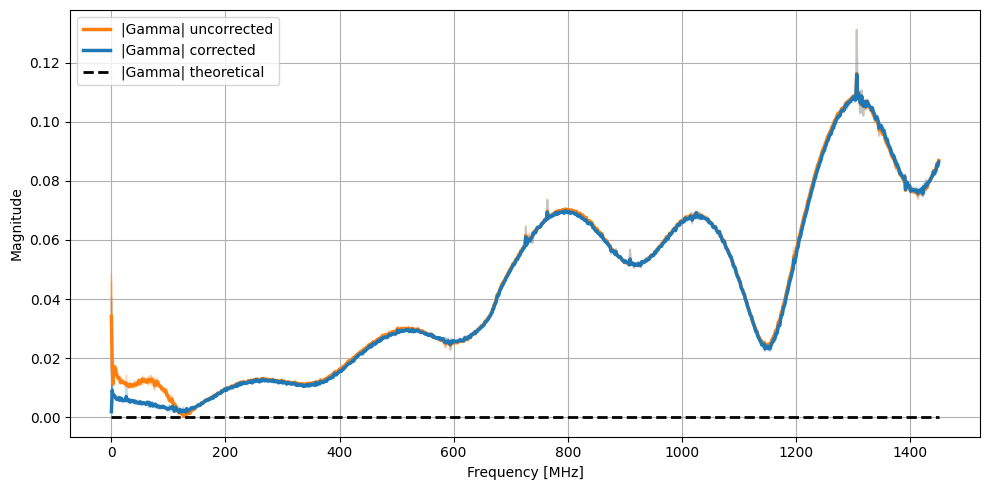

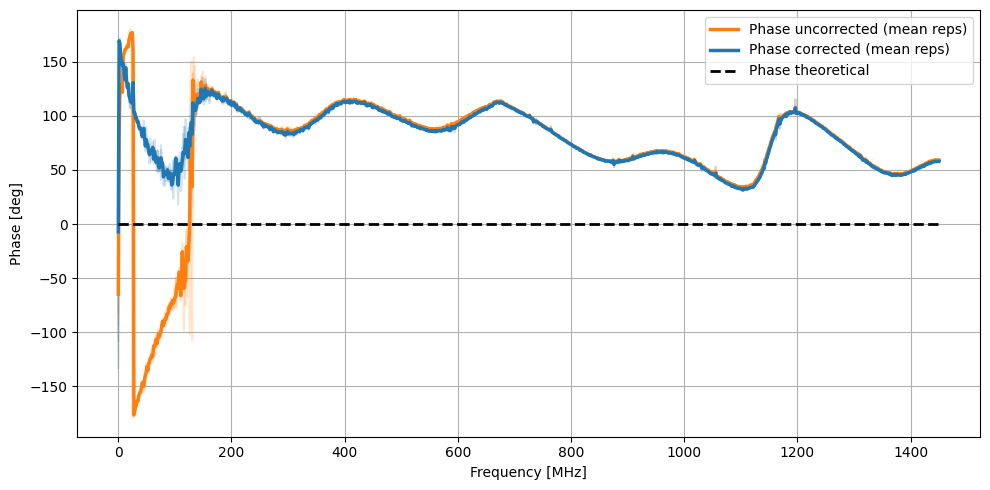

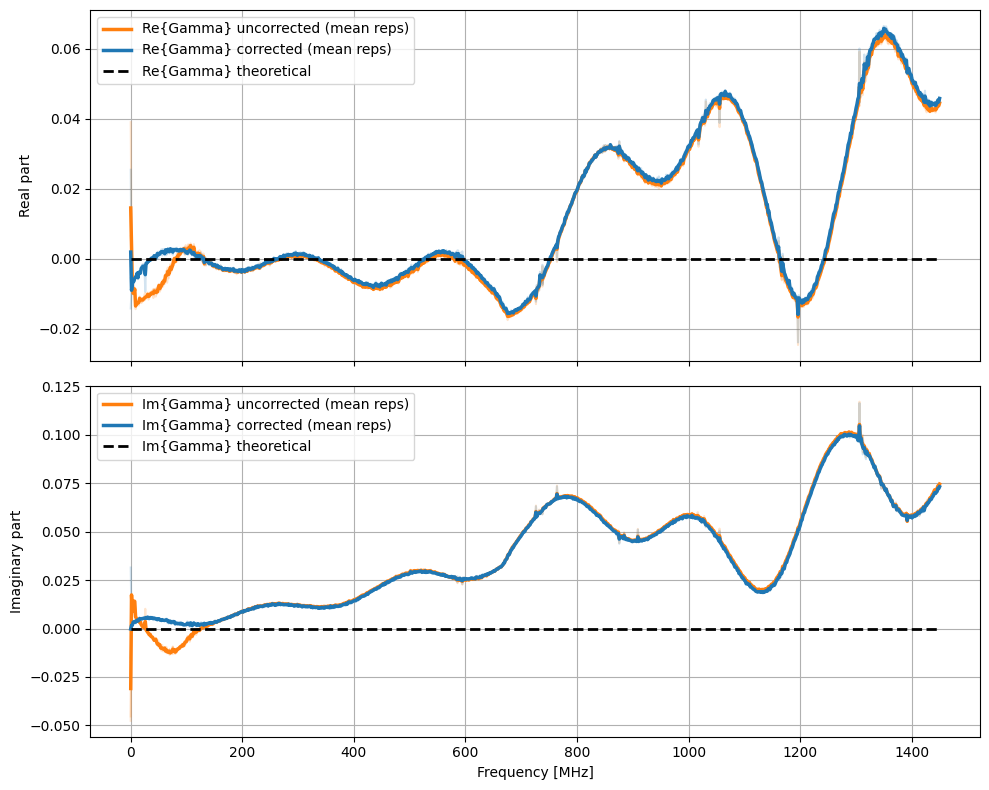

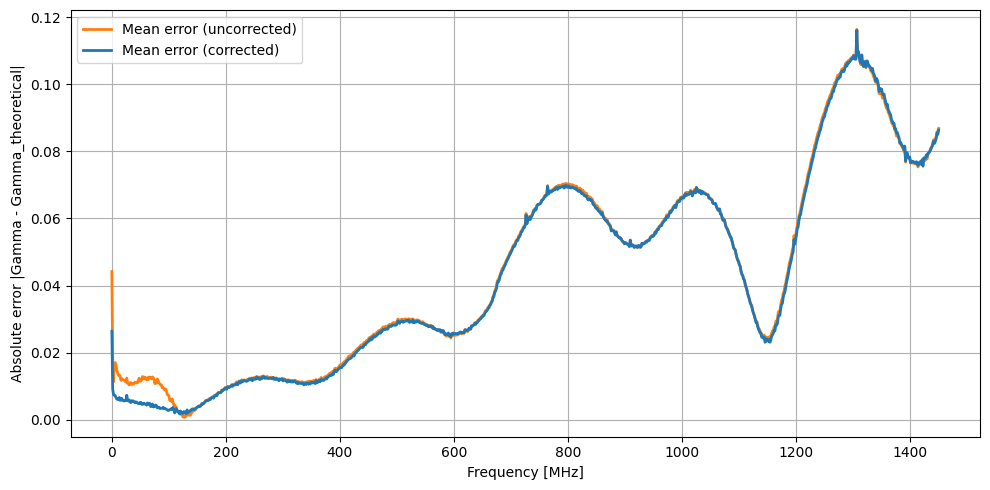

In [137]:

def load_error_terms(npz_file):
    data = np.load(npz_file)
    return data["freqs_hz"], data["ed"], data["er"], data["es"]


def interp_complex_linear(x_new, x, y):
    y_r = np.interp(x_new, x, y.real)
    y_i = np.interp(x_new, x, y.imag)
    return y_r + 1j * y_i


def apply_sol_correction(gamma_m, ed, er, es):
    # Inversion del modelo: Gamma = (Gamma_m - e_d) / (e_r + e_s*Gamma_m)
    denom = er + es * gamma_m
    tiny = 1e-15
    bad = np.abs(denom) < tiny
    if np.any(bad):
        denom = denom.copy()
        denom[bad] = tiny + 0j
    return (gamma_m - ed) / denom


def build_theoretical_vector(freqs_hz, gamma_theory):
    if callable(gamma_theory):
        out = np.asarray(gamma_theory(freqs_hz), dtype=complex)
    else:
        out = np.asarray(gamma_theory, dtype=complex)

    if out.ndim == 0:
        return np.full_like(freqs_hz, fill_value=out, dtype=complex)

    if out.shape[0] != freqs_hz.shape[0]:
        raise ValueError("GAMMA_THEORY debe ser escalar, callable(freqs)->array o array del mismo largo que freqs_hz")

    return out


def improvement_pct(raw_value, corr_value):
    if raw_value <= 0:
        return np.nan
    return 100.0 * (raw_value - corr_value) / raw_value


files = collect_standard_measure_files(MEASURE_STANDARD, measures_root=MEASURES_ROOT)
f_err, ed_err, er_err, es_err = load_error_terms(ERROR_TERMS_FILE)

if len(files) == 0:
    raise FileNotFoundError(f"No se encontraron archivos en {MEASURES_ROOT / MEASURE_STANDARD}")

freqs_ref = None
gamma_raw_all = []
gamma_corr_all = []

for idx, file_path in enumerate(files, start=1):
    freqs_hz, gamma_m = load_s11_from_touchstone(file_path)

    if freqs_ref is None:
        freqs_ref = freqs_hz
    elif not np.allclose(freqs_ref, freqs_hz):
        raise ValueError(f"Rejilla de frecuencias distinta en: {file_path}")

    ed_i = interp_complex_linear(freqs_hz, f_err, ed_err)
    er_i = interp_complex_linear(freqs_hz, f_err, er_err)
    es_i = interp_complex_linear(freqs_hz, f_err, es_err)

    gamma_corr = apply_sol_correction(gamma_m, ed_i, er_i, es_i)

    gamma_raw_all.append(gamma_m)
    gamma_corr_all.append(gamma_corr)
    print(f"[{MEASURE_STANDARD}] rep {idx:02d}: {file_path}")

gamma_raw_all = np.vstack(gamma_raw_all)
gamma_corr_all = np.vstack(gamma_corr_all)
gamma_theory = build_theoretical_vector(freqs_ref, GAMMA_THEORY)

# Errores por repeticion
err_raw = np.abs(gamma_raw_all - gamma_theory)
err_corr = np.abs(gamma_corr_all - gamma_theory)

# Error absoluto (MAE)
mae_raw_rep = np.mean(err_raw, axis=1)
mae_corr_rep = np.mean(err_corr, axis=1)
mae_raw_global = float(np.mean(err_raw))
mae_corr_global = float(np.mean(err_corr))

# Error cuadratico (RMSE)
rmse_raw_rep = np.sqrt(np.mean(err_raw**2, axis=1))
rmse_corr_rep = np.sqrt(np.mean(err_corr**2, axis=1))
rmse_raw_global = float(np.sqrt(np.mean(err_raw**2)))
rmse_corr_global = float(np.sqrt(np.mean(err_corr**2)))

# Error de cola (P95)
p95_raw_rep = np.percentile(err_raw, 95, axis=1)
p95_corr_rep = np.percentile(err_corr, 95, axis=1)
p95_raw_global = float(np.percentile(err_raw, 95))
p95_corr_global = float(np.percentile(err_corr, 95))

# Conversion a porcentaje en escala completa de |Gamma| (FS = 1)
mae_raw_pct_fs = 100.0 * mae_raw_rep
mae_corr_pct_fs = 100.0 * mae_corr_rep
mae_raw_global_pct_fs = 100.0 * mae_raw_global
mae_corr_global_pct_fs = 100.0 * mae_corr_global

rmse_raw_global_pct_fs = 100.0 * rmse_raw_global
rmse_corr_global_pct_fs = 100.0 * rmse_corr_global

# Error relativo porcentual respecto al teorico (cuando |Gamma_teorico| > 0)
theory_mag = np.abs(gamma_theory)
mean_theory_mag = float(np.mean(theory_mag))
show_relative_pct = mean_theory_mag > 1e-12
if show_relative_pct:
    mae_raw_rep_pct_rel = 100.0 * mae_raw_rep / mean_theory_mag
    mae_corr_rep_pct_rel = 100.0 * mae_corr_rep / mean_theory_mag
    mae_raw_global_pct_rel = 100.0 * mae_raw_global / mean_theory_mag
    mae_corr_global_pct_rel = 100.0 * mae_corr_global / mean_theory_mag

print("\n=== Metricas de error |Gamma - Gamma_teorico| ===")
for i in range(len(files)):
    imp_rep = improvement_pct(mae_raw_rep[i], mae_corr_rep[i])
    if show_relative_pct:
        print(
            f"rep {i+1:02d}: "
            f"MAE = {mae_raw_rep[i]:.6e} -> {mae_corr_rep[i]:.6e}, "
            f"error porcentual (%FS) = {mae_raw_pct_fs[i]:.3f}% -> {mae_corr_pct_fs[i]:.3f}%, "
            f"error relativo (%) = {mae_raw_rep_pct_rel[i]:.3f}% -> {mae_corr_rep_pct_rel[i]:.3f}%, "
            f"mejora = {imp_rep:.2f}%"
        )
    else:
        print(
            f"rep {i+1:02d}: "
            f"MAE = {mae_raw_rep[i]:.6e} -> {mae_corr_rep[i]:.6e}, "
            f"error porcentual (%FS) = {mae_raw_pct_fs[i]:.3f}% -> {mae_corr_pct_fs[i]:.3f}%, "
            f"error relativo (%) = N/A (|Gamma_teorico|~0), "
            f"mejora = {imp_rep:.2f}%"
        )

imp_mae_global = improvement_pct(mae_raw_global, mae_corr_global)
imp_rmse_global = improvement_pct(rmse_raw_global, rmse_corr_global)
imp_p95_global = improvement_pct(p95_raw_global, p95_corr_global)

print("\n--- Global ---")
print(
    f"MAE: {mae_raw_global:.6e} -> {mae_corr_global:.6e} | "
    f"error porcentual (%FS): {mae_raw_global_pct_fs:.3f}% -> {mae_corr_global_pct_fs:.3f}% | "
    f"mejora = {imp_mae_global:.2f}%"
)
if show_relative_pct:
    print(
        f"MAE relativo (%): {mae_raw_global_pct_rel:.3f}% -> {mae_corr_global_pct_rel:.3f}%"
    )
else:
    print("MAE relativo (%): N/A (|Gamma_teorico| medio es ~0, p.ej. carga ideal).")

print(
    f"RMSE: sin corregir = {rmse_raw_global:.6e} ({rmse_raw_global_pct_fs:.3f}%FS), "
    f"corregido = {rmse_corr_global:.6e} ({rmse_corr_global_pct_fs:.3f}%FS), "
    f"mejora = {imp_rmse_global:.2f}%"
)
print(
    f"P95(|error|): sin corregir = {p95_raw_global:.6e}, "
    f"corregido = {p95_corr_global:.6e}, mejora = {imp_p95_global:.2f}%"
)

# Promedios para visualizar tendencia
gamma_raw_mean = np.mean(gamma_raw_all, axis=0)
gamma_corr_mean = np.mean(gamma_corr_all, axis=0)
err_raw_mean = np.mean(err_raw, axis=0)
err_corr_mean = np.mean(err_corr, axis=0)

# Fase para visualizacion
phase_raw_all_deg = np.degrees(np.angle(gamma_raw_all))
phase_corr_all_deg = np.degrees(np.angle(gamma_corr_all))
phase_raw_mean_deg = np.degrees(np.angle(gamma_raw_mean))
phase_corr_mean_deg = np.degrees(np.angle(gamma_corr_mean))
phase_theory_deg = np.degrees(np.angle(gamma_theory))

freqs_mhz = freqs_ref / 1e6

# Magnitude plot (single y-axis)
plt.figure(figsize=(10, 5))
for i in range(gamma_raw_all.shape[0]):
    plt.plot(freqs_mhz, np.abs(gamma_raw_all[i]), color="tab:orange", alpha=0.25)
    plt.plot(freqs_mhz, np.abs(gamma_corr_all[i]), color="tab:blue", alpha=0.25)
plt.plot(freqs_mhz, np.abs(gamma_raw_mean), color="tab:orange", lw=2.5, label="|Gamma| uncorrected")
plt.plot(freqs_mhz, np.abs(gamma_corr_mean), color="tab:blue", lw=2.5, label="|Gamma| corrected")
plt.plot(freqs_mhz, np.abs(gamma_theory), "k--", lw=2, label="|Gamma| theoretical")
plt.xlabel("Frequency [MHz]")
plt.ylabel("Magnitude")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Phase plot (single y-axis)
plt.figure(figsize=(10, 5))
for i in range(phase_raw_all_deg.shape[0]):
    plt.plot(freqs_mhz, phase_raw_all_deg[i], color="tab:orange", alpha=0.20)
    plt.plot(freqs_mhz, phase_corr_all_deg[i], color="tab:blue", alpha=0.20)
plt.plot(freqs_mhz, phase_raw_mean_deg, color="tab:orange", lw=2.5, label="Phase uncorrected (mean reps)")
plt.plot(freqs_mhz, phase_corr_mean_deg, color="tab:blue", lw=2.5, label="Phase corrected (mean reps)")
plt.plot(freqs_mhz, phase_theory_deg, "k--", lw=2, label="Phase theoretical")
plt.xlabel("Frequency [MHz]")
plt.ylabel("Phase [deg]")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Complex Gamma components (real and imaginary)
fig, (ax_re, ax_im) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

for i in range(gamma_raw_all.shape[0]):
    ax_re.plot(freqs_mhz, gamma_raw_all[i].real, color="tab:orange", alpha=0.20)
    ax_re.plot(freqs_mhz, gamma_corr_all[i].real, color="tab:blue", alpha=0.20)
    ax_im.plot(freqs_mhz, gamma_raw_all[i].imag, color="tab:orange", alpha=0.20)
    ax_im.plot(freqs_mhz, gamma_corr_all[i].imag, color="tab:blue", alpha=0.20)

ax_re.plot(freqs_mhz, gamma_raw_mean.real, color="tab:orange", lw=2.5, label="Re{Gamma} uncorrected (mean reps)")
ax_re.plot(freqs_mhz, gamma_corr_mean.real, color="tab:blue", lw=2.5, label="Re{Gamma} corrected (mean reps)")
ax_re.plot(freqs_mhz, gamma_theory.real, "k--", lw=2, label="Re{Gamma} theoretical")
ax_re.set_ylabel("Real part")
ax_re.grid(True)
ax_re.legend()

ax_im.plot(freqs_mhz, gamma_raw_mean.imag, color="tab:orange", lw=2.5, label="Im{Gamma} uncorrected (mean reps)")
ax_im.plot(freqs_mhz, gamma_corr_mean.imag, color="tab:blue", lw=2.5, label="Im{Gamma} corrected (mean reps)")
ax_im.plot(freqs_mhz, gamma_theory.imag, "k--", lw=2, label="Im{Gamma} theoretical")
ax_im.set_xlabel("Frequency [MHz]")
ax_im.set_ylabel("Imaginary part")
ax_im.grid(True)
ax_im.legend()

fig.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(freqs_mhz, err_raw_mean, color="tab:orange", lw=2, label="Mean error (uncorrected)")
plt.plot(freqs_mhz, err_corr_mean, color="tab:blue", lw=2, label="Mean error (corrected)")
plt.xlabel("Frequency [MHz]")
plt.ylabel("Absolute error |Gamma - Gamma_theoretical|")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

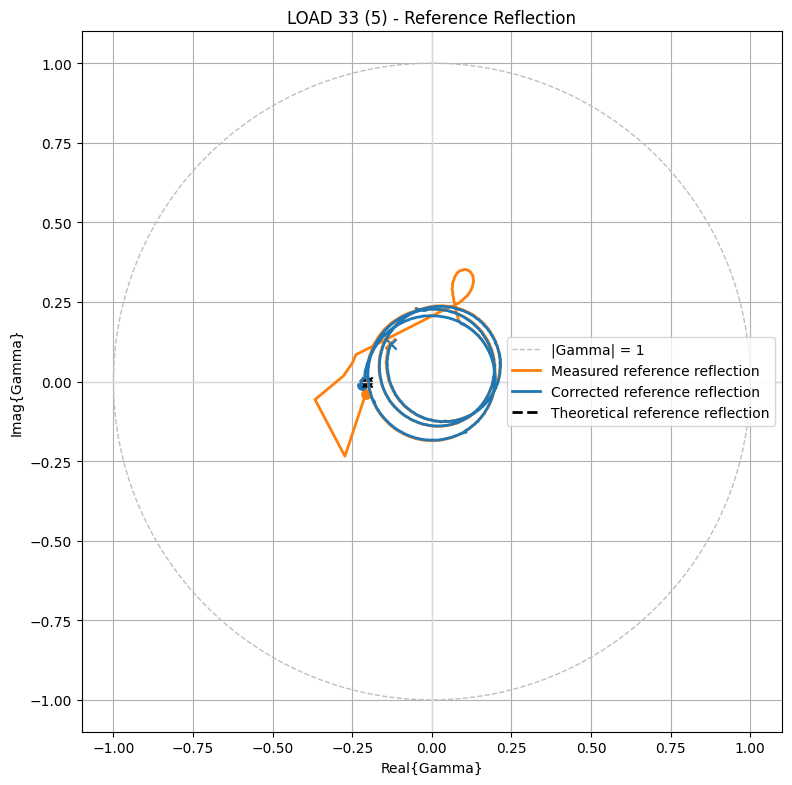

In [131]:
# Reference reflection in the complex plane
# Requires cell 6 to be executed first.

if "gamma_raw_mean" not in globals() or "gamma_corr_mean" not in globals() or "gamma_theory" not in globals():
    raise RuntimeError("Run cell 6 first to compute gamma_raw_mean, gamma_corr_mean, and gamma_theory.")

fig, ax = plt.subplots(figsize=(8, 8))

# Unit circle for reference
angles = np.linspace(0, 2 * np.pi, 512)
ax.plot(np.cos(angles), np.sin(angles), color="0.75", lw=1.0, ls="--", label="|Gamma| = 1")
ax.axhline(0.0, color="0.85", lw=1)
ax.axvline(0.0, color="0.85", lw=1)

# Mean traces
ax.plot(gamma_raw_mean.real, gamma_raw_mean.imag, color="tab:orange", lw=2.0, label="Measured reference reflection")
ax.plot(gamma_corr_mean.real, gamma_corr_mean.imag, color="tab:blue", lw=2.0, label="Corrected reference reflection")
ax.plot(gamma_theory.real, gamma_theory.imag, color="black", lw=2.0, ls="--", label="Theoretical reference reflection")

# Start/end markers across the sweep
ax.scatter(gamma_raw_mean.real[0], gamma_raw_mean.imag[0], color="tab:orange", s=45, marker="o")
ax.scatter(gamma_raw_mean.real[-1], gamma_raw_mean.imag[-1], color="tab:orange", s=55, marker="x")
ax.scatter(gamma_corr_mean.real[0], gamma_corr_mean.imag[0], color="tab:blue", s=45, marker="o")
ax.scatter(gamma_corr_mean.real[-1], gamma_corr_mean.imag[-1], color="tab:blue", s=55, marker="x")

# Theoretical trace may be constant or frequency-dependent
ax.scatter(gamma_theory.real[0], gamma_theory.imag[0], color="black", s=45, marker="o")
ax.scatter(gamma_theory.real[-1], gamma_theory.imag[-1], color="black", s=55, marker="x")

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Real{Gamma}")
ax.set_ylabel("Imag{Gamma}")
ax.set_title(f"{MEASURE_STANDARD.upper()} - Reference Reflection")
ax.grid(True)
ax.legend(loc="best")
plt.tight_layout()
plt.show()